# EU Gender Pay Gap Analysis
## Notebook 5: Age Group Analysis — How the Gap Changes With Age

**Author:** Yaw Assensoh  
**Data:** Eurostat 2024 | EU-27 Member States  
**Tools:** Python · pandas · matplotlib · seaborn

---

The headline pay gap is an average over all workers. This notebook splits it by age group to see whether it is the same at every stage of a career.

One common explanation for a gap that grows in mid-career is unequal caring responsibilities (often called the motherhood penalty). This data contains no information on parenthood or working hours, so it cannot test that explanation. It can show *where in the age range* the gap changes.

### This notebook answers:
1. At what age does the gap start to widen?
2. Does the pattern look the same in every EU region?
3. Which countries show the biggest increase between Under 25 and 35–44?
4. Has that increase changed since 2010?

---
## Step 1: Import libraries

In [3]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns   
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings('ignore')

# consistent style
plt.rcParams.update({
    'figure.dpi'        : 150,
    'font.family'       : 'sans-serif',
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.titlesize'    : 13,
    'axes.titleweight'  : 'bold',
    'axes.labelsize'    : 11,
    'xtick.labelsize'   : 9,
    'ytick.labelsize'   : 9,
    'figure.facecolor'    : 'white',
    'axes.facecolor'     : '#F7FBFF',})

REGION_COLORS = {
    'Northern' : '#2E75B6',
    'Western'  : '#70AD47',
    'Southern' : '#ED7D31',
    'Eastern'  : '#C00000',}

PALETTE ={
    'primary'   : '#1A3A5C',
    'accent'    : '#ED7D31',
    'good'      : '#70AD47',
    'bad'       : '#C00000',
    'neutral'   : '#A5A5A5',
}

# Correct age group sort order — critical for charts to read left to right
AGE_ORDER = [
    'Under 25', '25-34', '35-44',
    '45-54',    '55-64', '65+']

---
## Step 2: Load dataset

In [4]:
# load data
gpg_age = pd.read_csv('../data/clean/gpg_age.csv')
gpg_main = pd.read_csv('../data/clean/gpg_main.csv')


# Enforce correct age order as a categorical variable
# This ensures charts always display age groups left to right
gpg_age['age_group'] = pd.Categorical(
    gpg_age['age_group'],
    categories=AGE_ORDER,
    ordered=True
)

# Latest available year per country-age combination
latest_age = (
    gpg_age
    .sort_values('year')
    .groupby(['country', 'age_group', 'eu_region'])
    .last()
    .reset_index()
)

# EU average per age group across all countries
eu_age_avg = (
    latest_age
    .groupby('age_group')['gpg_pct']
    .mean()
    .round(1)
    .reset_index()
)
eu_age_avg.columns = ['age_group', 'eu_avg_gap']

print(f" Data loaded")
print(f"   Age groups  : {sorted(gpg_age['age_group'].unique().tolist())}")
print(f"   Countries   : {gpg_age['country'].nunique()}")
print(f"   Year range  : {gpg_age['year'].min()}–{gpg_age['year'].max()}")
print()
print("EU average pay gap by age group:")
print(eu_age_avg.to_string(index=False))

 Data loaded
   Age groups  : ['25-34', '35-44', '45-54', '55-64', '65+', 'Under 25']
   Countries   : 27
   Year range  : 2007–2024

EU average pay gap by age group:
age_group  eu_avg_gap
 Under 25         3.9
    25-34         6.7
    35-44        11.2
    45-54        12.9
    55-64        11.7
      65+        11.4


---
## Step 3: Age group charts

## The EU Average Gap at Each Life Stage

We start with the simplest version of the story: the EU average
pay gap at each age group, from the youngest workers to the oldest.

This chart is deliberately simple. Its power comes from the shaape
a curve that starts low, rises sharply, and never comes back down.
That shape is the motherhood penalty made visible.

Each bar also shows the actual percentage so we can quantify
exactly how much the gap grows at each life stage.

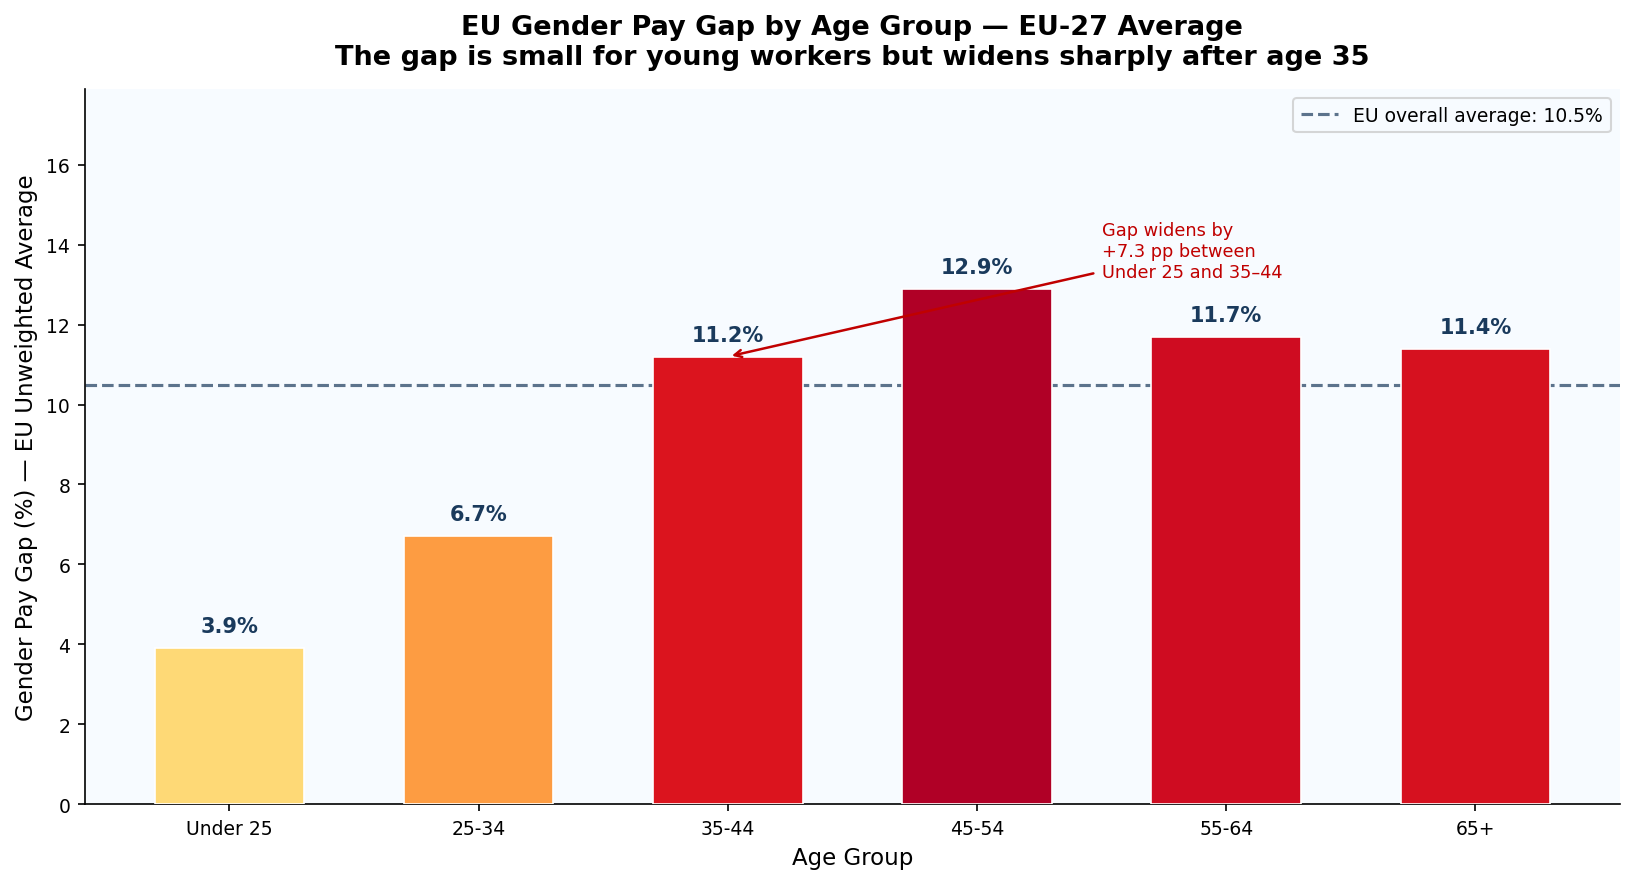

In [7]:
# Bar chart of EU average gap by age group
fig, ax = plt.subplots(figsize=(11, 6))

# Colour bars by size — light for low gap, dark red for high
norm_vals = (
    eu_age_avg['eu_avg_gap'] - eu_age_avg['eu_avg_gap'].min()
) / (
    eu_age_avg['eu_avg_gap'].max() - eu_age_avg['eu_avg_gap'].min()
)
bar_colors = [plt.cm.YlOrRd(0.25 + 0.65 * v) for v in norm_vals]

bars = ax.bar(
    eu_age_avg['age_group'],
    eu_age_avg['eu_avg_gap'],
    color=bar_colors,
    edgecolor='white',
    linewidth=0.8,
    width=0.6,
    zorder=3
)

# Value labels on top of each bar
for bar, val in zip(bars, eu_age_avg['eu_avg_gap']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f'{val:.1f}%',
        ha='center', va='bottom',
        fontsize=10, fontweight='bold',
        color=PALETTE['primary']
    )

# Annotate the key turning point — 25-34 to 35-44
under25_val = eu_age_avg.loc[
    eu_age_avg['age_group'] == 'Under 25', 'eu_avg_gap'
].values[0]
age3544_val = eu_age_avg.loc[
    eu_age_avg['age_group'] == '35-44', 'eu_avg_gap'
].values[0]
jump = round(age3544_val - under25_val, 1)

ax.annotate(
    f'Gap widens by\n+{jump} pp between\nUnder 25 and 35–44',
    xy=(2, age3544_val),
    xytext=(3.5, age3544_val + 2),
    fontsize=8.5,
    color=PALETTE['bad'],
    arrowprops=dict(
        arrowstyle='->',
        color=PALETTE['bad'],
        lw=1.2
    )
)

# EU overall average reference line
overall_avg = round(
    gpg_main[gpg_main['year'] == 2024]['gpg_pct'].mean(), 1
)
ax.axhline(
    overall_avg,
    color=PALETTE['primary'],
    linewidth=1.5,
    linestyle='--',
    alpha=0.7,
    label=f'EU overall average: {overall_avg}%'
)

ax.set_title(
    'EU Gender Pay Gap by Age Group — EU-27 Average\n'
    'The gap is small for young workers but widens sharply after age 35',
    pad=12
)
ax.set_xlabel('Age Group')
ax.set_ylabel('Gender Pay Gap (%) — EU Unweighted Average')
ax.legend(fontsize=9)
ax.set_ylim(0, eu_age_avg['eu_avg_gap'].max() + 5)

plt.tight_layout()
plt.savefig('../reports/figures/05_01_age_group_eu_avg.png',
            dpi=150, bbox_inches='tight')
plt.show()

### What this tells us

Using each country's latest available year, the EU average gap is 3.9% for under-25s, 6.7% for 25–34, 11.2% for 35–44, 12.9% for 45–54, 11.7% for 55–64 and 11.4% for 65+.

**The gap is smallest for the youngest workers and rises sharply between 25–34 and 35–44.** After 45 it stays at a similar level (11–13%).

This shows an association with age. It does not show why. Career breaks, part-time work and caring responsibilities are commonly proposed explanations, but they are not measured in this data.

Lower earnings over a career can also affect pensions, but that is outside the scope of this dataset.

---
# Step 4: Age by region line charts

## Does the Motherhood Penalty Look the Same across All EU Regions?

The EU average smooths over very different regional experiences.
A Nordic country with generous parental leave and subsidised
childcare might show a very different age profile from an
Eastern European country with fewer such supports.

We now split the analysis by EU region to see whether the
motherhood penalty is a universal EU pattern or whether
it is concentrated in specific parts of Europe.

Each line represents one EU region. If the lines follow
the same shape, the penalty is universal.
If they diverge, regional policy and culture matter.

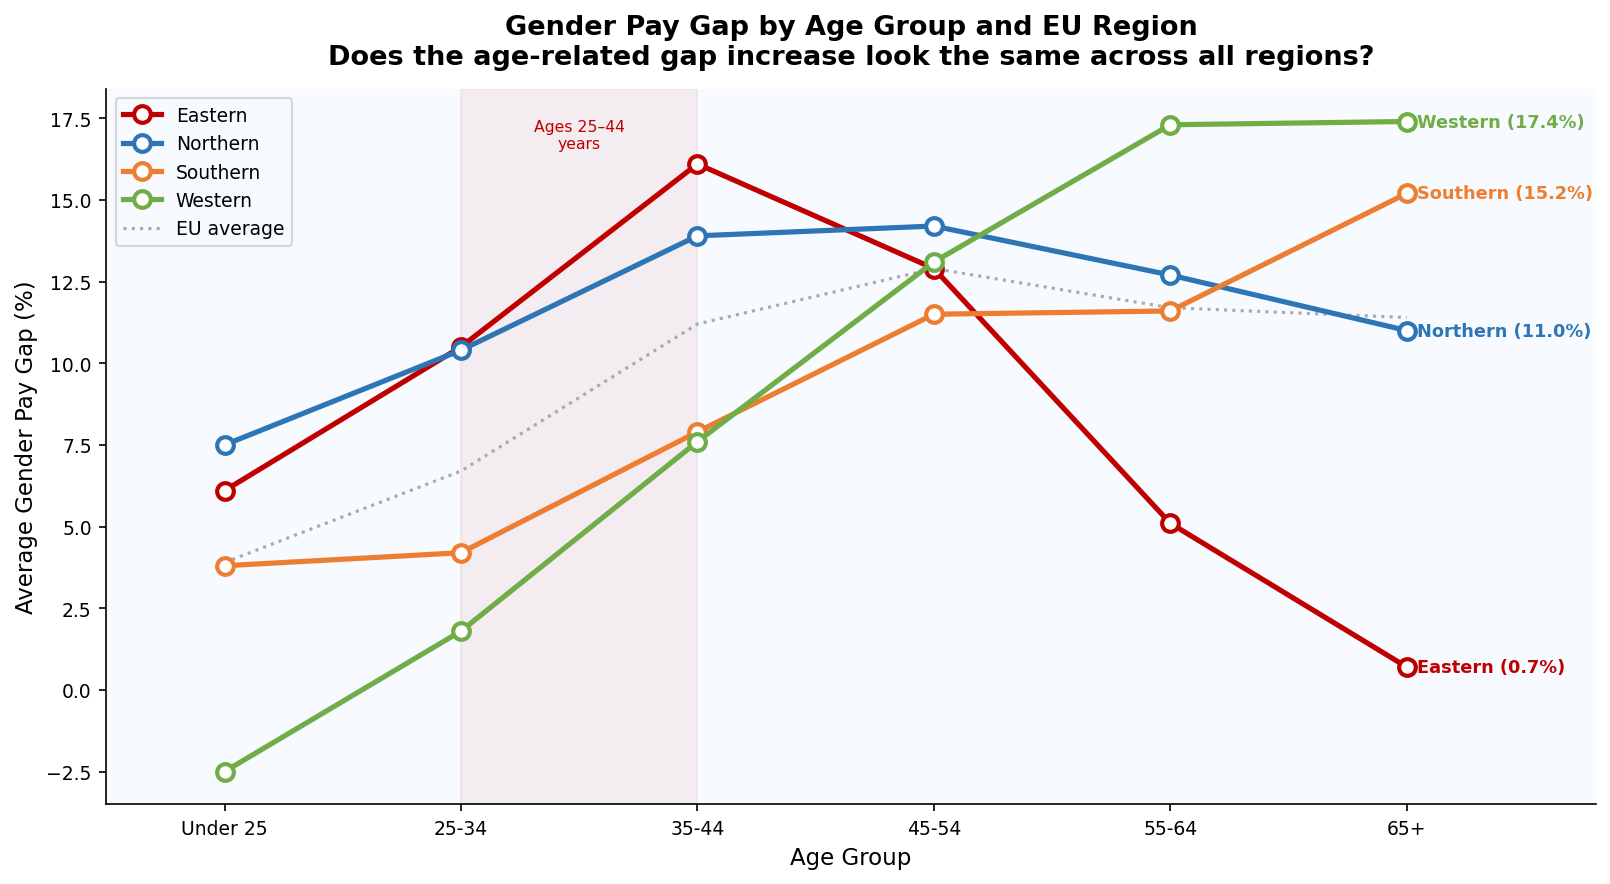

Average pay gap by region and age group:
age_group  Under 25  25-34  35-44  45-54  55-64   65+
eu_region                                            
Eastern         6.1   10.5   16.1   12.9    5.1   0.7
Northern        7.5   10.4   13.9   14.2   12.7  11.0
Southern        3.8    4.2    7.9   11.5   11.6  15.2
Western        -2.5    1.8    7.6   13.1   17.3  17.4


In [5]:
# Line chart of pay gap by age group, split by EU region
region_age_avg = (
    latest_age
    .groupby(['eu_region', 'age_group'])['gpg_pct']
    .mean()
    .round(1)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 6))

for region, group in region_age_avg.groupby('eu_region'):
    group_sorted = group.sort_values('age_group')
    ax.plot(
        group_sorted['age_group'].astype(str),
        group_sorted['gpg_pct'],
        color=REGION_COLORS[region],
        linewidth=2.5,
        marker='o',
        markersize=8,
        markerfacecolor='white',
        markeredgewidth=2,
        label=region,
        zorder=3
    )
    # End label
    last = group_sorted.iloc[-1]
    ax.annotate(
        f"{region} ({last['gpg_pct']:.1f}%)",
        xy=(5, last['gpg_pct']),
        xytext=(5, 0),
        textcoords='offset points',
        fontsize=8.5,
        color=REGION_COLORS[region],
        va='center',
        fontweight='bold'
    )

# EU average line for reference
eu_line = eu_age_avg.copy()
ax.plot(
    eu_line['age_group'].astype(str),
    eu_line['eu_avg_gap'],
    color='#AAAAAA',
    linewidth=1.5,
    linestyle=':',
    label='EU average',
    zorder=2)

# Shade the childbearing years
ax.axvspan(1, 2, alpha=0.06, color=PALETTE['bad'])
ax.text(
    1.5, ax.get_ylim()[1] * 0.95 if ax.get_ylim()[1] > 0 else 18,
    'Ages 25–44\nyears',
    ha='center', fontsize=7.5,
    color=PALETTE['bad'], va='top')

ax.set_title(
    'Gender Pay Gap by Age Group and EU Region\n'
    'Does the age-related gap increase look the same across all regions?',
    pad=12
)
ax.set_xlabel('Age Group')
ax.set_ylabel('Average Gender Pay Gap (%)')
ax.legend(fontsize=9, loc='upper left')
ax.set_xlim(-0.5, 5.8)

plt.tight_layout()
plt.savefig('../reports/figures/05_02_age_by_region.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("Average pay gap by region and age group:")
print(
    region_age_avg.pivot(
        index='eu_region',
        columns='age_group',
        values='gpg_pct'
    ).to_string()
)

### What this tells us

The regions do **not** share one shape. Averages by region and age group (latest year per country):

| Region | Under 25 | 35–44 | 65+ |
|---|---|---|---|
| Eastern | 6.1 | 16.1 | 0.7 |
| Northern | 7.5 | 13.9 | 11.0 |
| Southern | 3.8 | 7.9 | 15.2 |
| Western | −2.5 | 7.6 | 17.4 |

**What is common:** in every region the gap at 35–44 is larger than for under-25s.

**What differs:** Eastern Europe peaks at 35–44 (16.1%) and falls to 0.7% by 65+. Southern and Western Europe keep rising to the oldest group. Northern Europe rises to 45–54 and then eases slightly.

Each region has only 6–8 countries, so these averages are sensitive to individual countries. The reasons for the differences are not tested here.
The universality of the upward slope is the most important
finding: **better parental leave policies reduce the level
of the penalty but have not eliminated its shape.**
The gap always widens after 35 regardless of region.

--- 
## Step 5: Penalty ranking

## Which Countries Show the Biggest Increase?

Now we compare each country's Under 25 gap with its 35–44 gap and rank the difference. A larger number means the gap grows more between those two age groups.

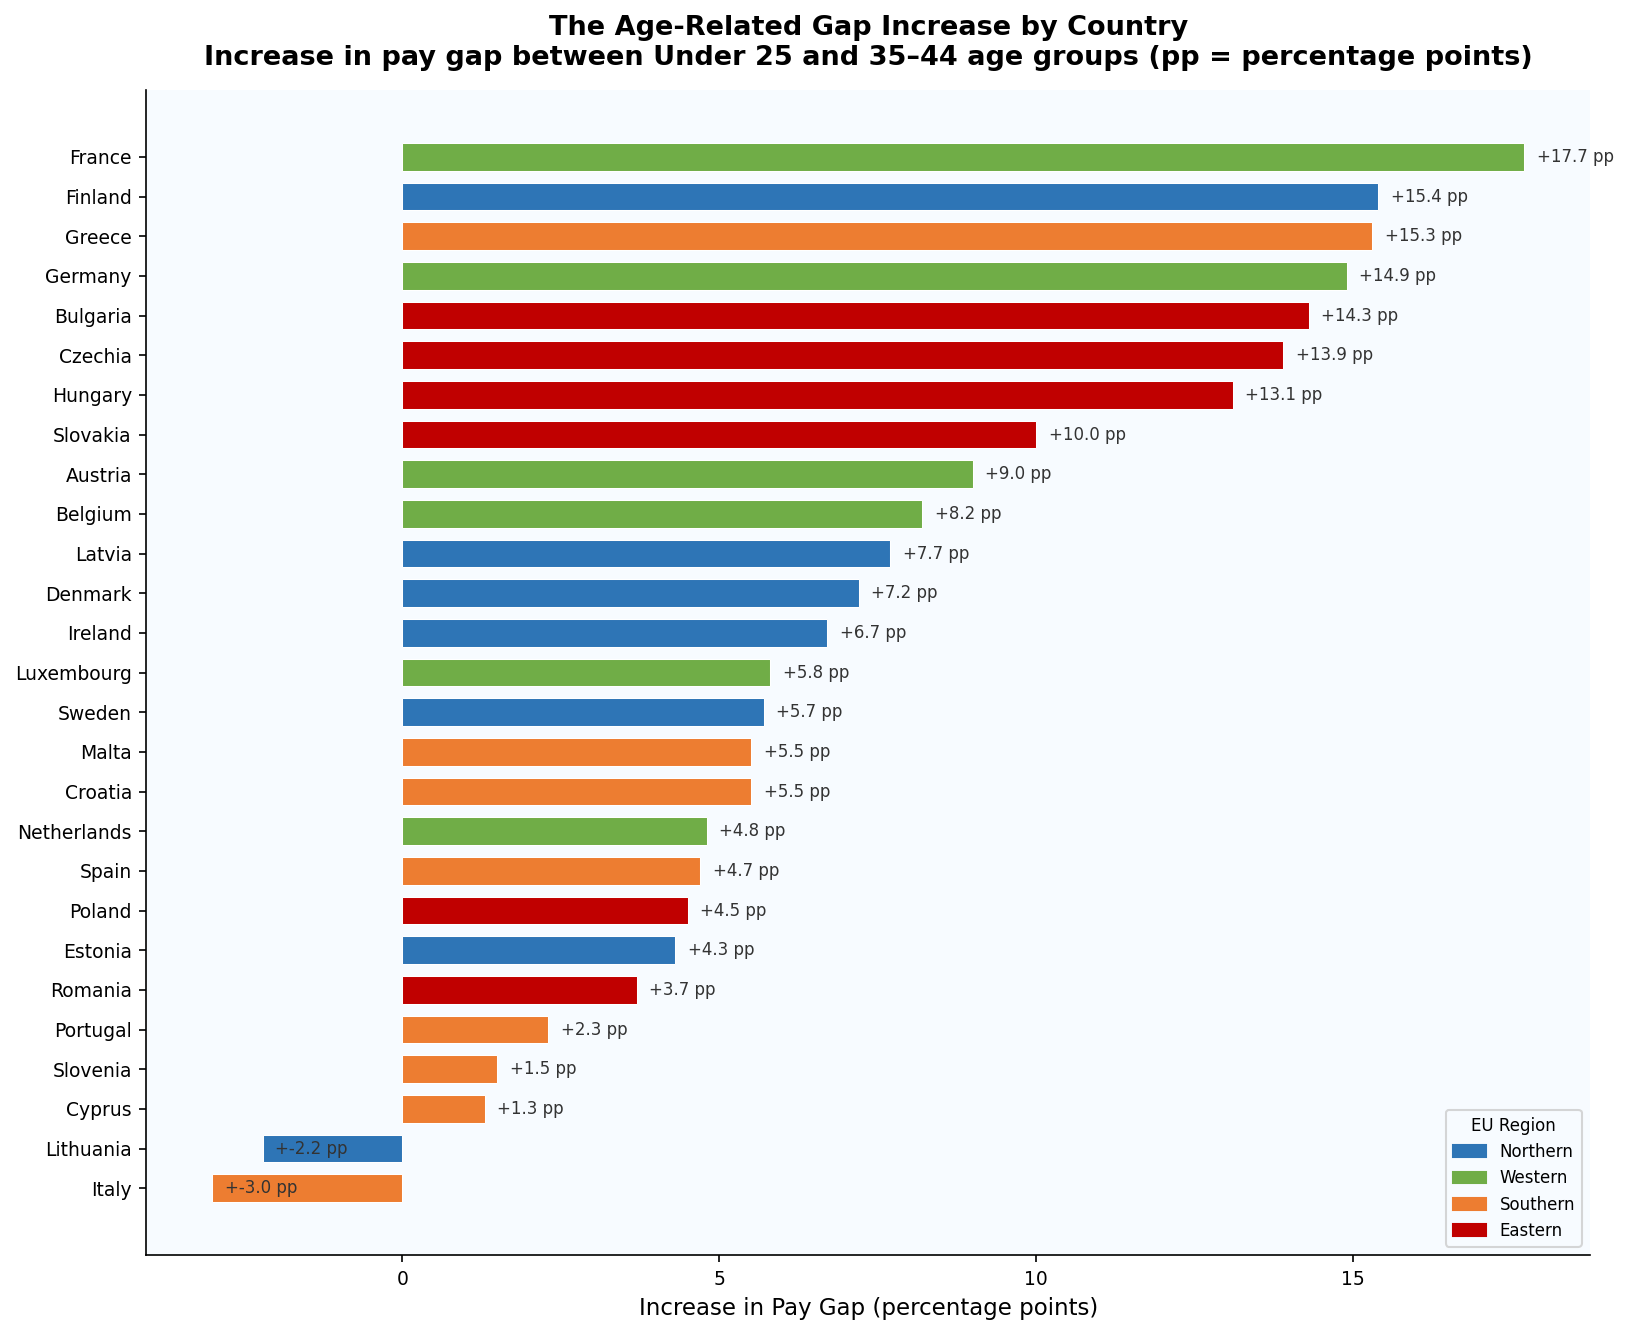

Top 10 countries with sharpest age-related gap increase:
 country eu_region  gap_under25  gap_3544  penalty_pp
  France   Western         -5.2      12.5        17.7
 Finland  Northern         -1.1      14.3        15.4
  Greece  Southern         -3.4      11.9        15.3
 Germany   Western         -0.4      14.5        14.9
Bulgaria   Eastern          5.3      19.6        14.3
 Czechia   Eastern          7.7      21.6        13.9
 Hungary   Eastern          8.5      21.6        13.1
Slovakia   Eastern          8.7      18.7        10.0
 Austria   Western          9.1      18.1         9.0
 Belgium   Western         -8.3      -0.1         8.2


In [7]:
# Get Under 25 and 35-44 gap per country
under25 = (
    latest_age[latest_age['age_group'] == 'Under 25']
    [['country', 'eu_region', 'gpg_pct']]
    .rename(columns={'gpg_pct': 'gap_under25'})
)

age3544 = (
    latest_age[latest_age['age_group'] == '35-44']
    [['country', 'gpg_pct']]
    .rename(columns={'gpg_pct': 'gap_3544'})
)

penalty = under25.merge(age3544, on='country', how='inner')
penalty['penalty_pp'] = (
    penalty['gap_3544'] - penalty['gap_under25']
).round(1)
penalty = penalty.sort_values('penalty_pp', ascending=False)

fig, ax = plt.subplots(figsize=(11, 9))

bar_colors = [
    REGION_COLORS.get(r, PALETTE['neutral'])
    for r in penalty['eu_region']
]

bars = ax.barh(
    penalty['country'],
    penalty['penalty_pp'],
    color=bar_colors,
    edgecolor='white',
    linewidth=0.5,
    height=0.7
)

# Value labels
for bar, val in zip(bars, penalty['penalty_pp']):
    ax.text(
        val + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f'+{val:.1f} pp',
        va='center', ha='left',
        fontsize=8, color='#333333'
    )

# Region legend
legend_patches = [
    mpatches.Patch(color=c, label=r)
    for r, c in REGION_COLORS.items()
]
ax.legend(
    handles=legend_patches,
    title='EU Region',
    fontsize=8,
    title_fontsize=8,
    loc='lower right'
)

ax.set_title(
    'The Age-Related Gap Increase by Country\n'
    'Increase in pay gap between Under 25 and 35–44 age groups (pp = percentage points)',
    pad=12
)
ax.set_xlabel('Increase in Pay Gap (percentage points)')
ax.set_ylabel('')
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('../reports/figures/05_03_motherhood_penalty_ranking.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("Top 10 countries with sharpest age-related gap increase:")
print(
    penalty.head(10)[
        ['country', 'eu_region', 'gap_under25', 'gap_3544', 'penalty_pp']
    ].to_string(index=False))

### What this tells us

The ranking shows how much the gap grows between Under 25 and 35–44 in each country. Read it as a description of the data: the size of the increase varies a lot between countries.

Explanations for why some countries show bigger increases (for example differences in childcare or leave policy) would need additional data to test.

---
## Step 6: Change over time

## Has the Increase Changed Since 2010?

We compare each country's 35–44 gap in 2010 with its latest value. A negative change means the gap for that age group has narrowed.

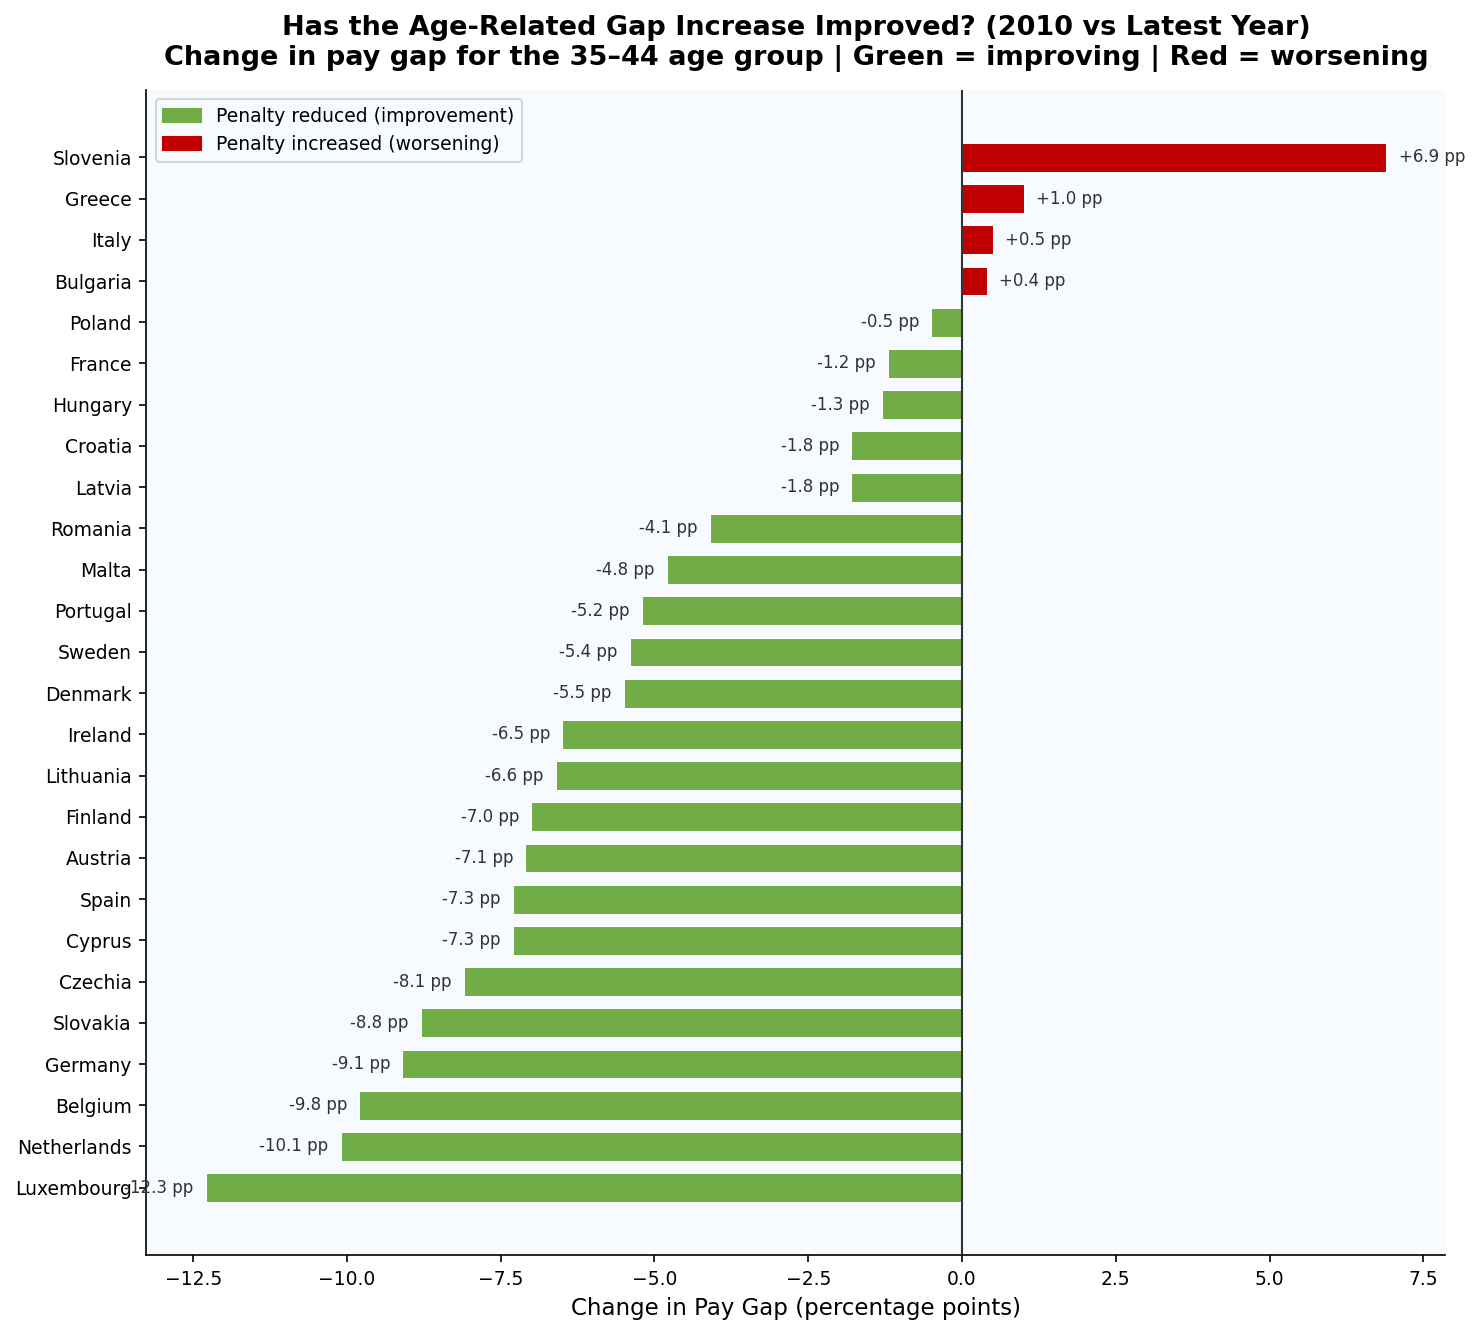

Countries where penalty improved : 22
Countries where penalty worsened : 4
Countries with no change         : 0


In [8]:
# Change over time: how has the age-related gap increase evolved since 2010?
age3544_2010 = (
    gpg_age[
        (gpg_age['age_group'] == '35-44') &
        (gpg_age['year'] == 2010)
    ][['country', 'gpg_pct']]
    .rename(columns={'gpg_pct': 'gap_2010'})
)

age3544_2024 = (
    gpg_age[
        (gpg_age['age_group'] == '35-44') &
        (gpg_age['year'] == 2024)
    ][['country', 'gpg_pct']]
    .rename(columns={'gpg_pct': 'gap_2024'})
)

# Use latest available if 2024 missing
age3544_latest = (
    gpg_age[gpg_age['age_group'] == '35-44']
    .sort_values('year')
    .groupby('country')
    .last()
    .reset_index()[['country', 'gpg_pct']]
    .rename(columns={'gpg_pct': 'gap_latest'})
)

change = age3544_2010.merge(age3544_latest, on='country', how='inner')
change['change_pp'] = (change['gap_latest'] - change['gap_2010']).round(1)
change = change.sort_values('change_pp', ascending=True)

bar_colors = [
    PALETTE['good'] if v < 0 else PALETTE['bad']
    for v in change['change_pp']
]

fig, ax = plt.subplots(figsize=(10, 9))

bars = ax.barh(
    change['country'],
    change['change_pp'],
    color=bar_colors,
    edgecolor='white',
    linewidth=0.5,
    height=0.7
)

ax.axvline(0, color='#333333', linewidth=1, zorder=5)

for bar, val in zip(bars, change['change_pp']):
    x_pos = val - 0.2 if val < 0 else val + 0.2
    ha = 'right' if val < 0 else 'left'
    ax.text(
        x_pos,
        bar.get_y() + bar.get_height() / 2,
        f'{val:+.1f} pp',
        va='center', ha=ha,
        fontsize=8, color='#333333'
    )

improved = mpatches.Patch(
    color=PALETTE['good'], label='Penalty reduced (improvement)'
)
worsened = mpatches.Patch(
    color=PALETTE['bad'],  label='Penalty increased (worsening)'
)
ax.legend(handles=[improved, worsened], fontsize=9)

ax.set_title(
    'Has the Age-Related Gap Increase Improved? (2010 vs Latest Year)\n'
    'Change in pay gap for the 35–44 age group | '
    'Green = improving | Red = worsening',
    pad=12
)
ax.set_xlabel('Change in Pay Gap (percentage points)')
ax.set_ylabel('')

plt.tight_layout()
plt.savefig('../reports/figures/05_04_penalty_change_over_time.png',
            dpi=150, bbox_inches='tight')
plt.show()

improved_count = (change['change_pp'] < 0).sum()
worsened_count = (change['change_pp'] > 0).sum()
print(f"Countries where penalty improved : {improved_count}")
print(f"Countries where penalty worsened : {worsened_count}")
print(f"Countries with no change         : {(change['change_pp'] == 0).sum()}")

### What this tells us

For the 35–44 age group, the gap narrowed in 22 of the 26 countries with data and widened in 4. So for most countries this age group has improved since 2010.

The countries where it widened are worth examining individually, since they run against the overall direction. This analysis does not explain why.

---
## Complete — Key Findings

| Finding | Detail |
|---|---|
| **Smallest gap for the youngest workers** | 3.9% for under-25s (EU average, latest year) |
| **Sharpest rise between 25–34 and 35–44** | 6.7% to 11.2% |
| **A common feature across regions** | In all four regions the gap at 35–44 exceeds the under-25 gap |
| **Regions differ after that** | Eastern Europe falls back after 45; Southern and Western Europe keep rising |
| **Most countries have improved since 2010** | The 35–44 gap narrowed in 22 of 26 countries |
| **Limits** | Age pattern is an association; parenthood and hours are not in the data |

**Next → Notebook 6: Statistical Testing**
